<a href="https://colab.research.google.com/github/tristanwalmsley/CO3519_Artificial-Intelligence_Lab3_Linear-Regression/blob/main/AI_Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training data shape: (14448, 8)
Testing data shape: (6192, 8)
Mean Squared Error: 0.5305677824766758
Root Mean Squared Error: 0.7284008391515456


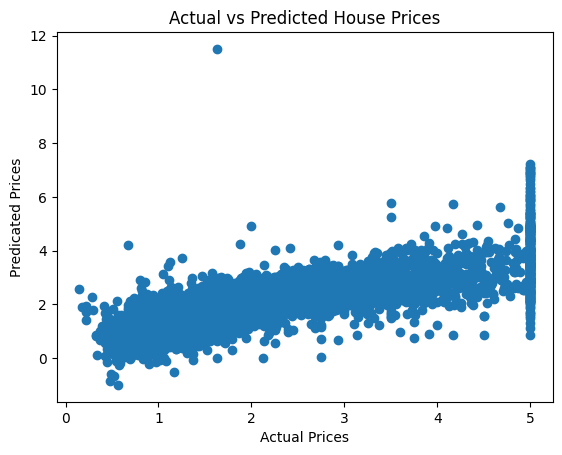

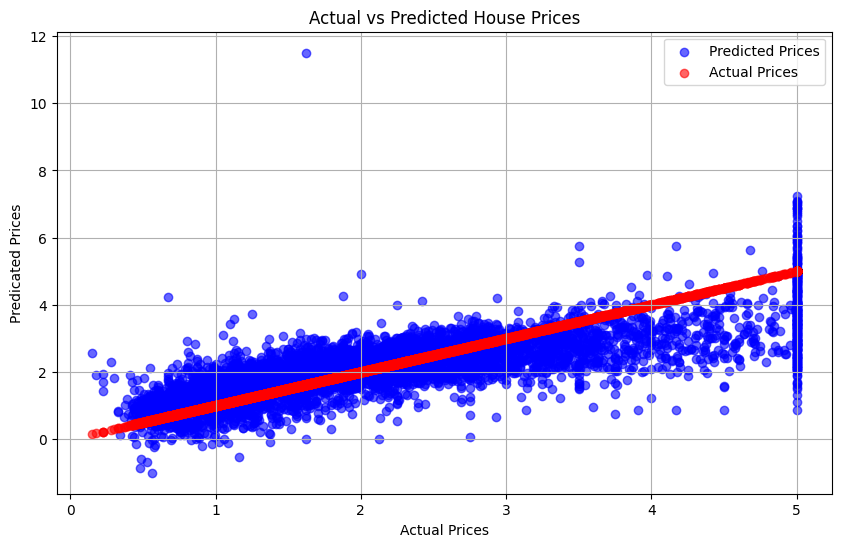

       Actual  Predicted
0     0.14999   2.578707
1     0.17500   1.906902
2     0.22500   1.946262
3     0.22500   1.703778
4     0.22500   1.422030
...       ...        ...
6187  5.00001   4.906688
6188  5.00001   4.853687
6189  5.00001   5.410385
6190  5.00001   5.718841
6191  5.00001   5.411810

[6192 rows x 2 columns]


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()

data = pd.DataFrame(housing.data, columns=housing.feature_names)
data['PRICE'] = housing.target

data.head()

X = data.drop('PRICE', axis=1)
y = data['PRICE']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Prices")
plt.ylabel("Predicated Prices")
plt.title("Actual vs Predicted House Prices")
plt.show()

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color='blue', label='Predicted Prices', alpha=0.6)
plt.scatter(y_test, y_test, color='red', label='Actual Prices', alpha=0.6)
plt.xlabel("Actual Prices")
plt.ylabel("Predicated Prices")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.grid()
plt.show()

results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})

results_sorted = results.sort_values(by='Actual').reset_index(drop=True)

print(results_sorted)
